## MNIST and Fashion MNIST

The MNIST dataset consists of 70K handwritten digits with 10 classes corresponding to digits 0-9. Each 28x28 image within the dataset consists of a 28x28 (784 total) pixel depiction of a particular digit. A widely used benchmark in machine learning classification testing, MNIST will serve as one of the datasets examined.

The Fashion-MNIST dataset is a dataset of Zalando's article images - rather than digits used in the original MNIST dataset, the Fashion-MNIST dataset consists of images of clothing articles that share the same overall characteristics of the original MNIST dataset - 70K total images, greyscale, 28x28 pixel images. The Fashion-MNIST was developed as a potential replacement to the original MNIST dataset, and will serve as a secondary dataset to examine.

The overall goal of this project is to examine various sci-kit prediction techniques and hyperparameter tuning to examine:
1. The performance of these prediction techniques on each dataset
2. The difference of the same prediction technique between the MNIST and Fashion-MNIST dataset

In [23]:
import time
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.datasets import fashion_mnist

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)


In [2]:
# Loading the original MNIST dataset
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = mnist.load_data()

print(X_train_mnist.shape)
print(y_train_mnist.shape)
print(X_test_mnist.shape)
print(y_test_mnist.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [ ]:
# Loading the Fashion MNIST dataset
# We also define the actual class names for the Fashion MNIST dataset, as noted on Kaggle: https://www.kaggle.com/datasets/zalando-research/fashionmnist
(X_train_fashion_mnist, y_train_fashion_mnist), (X_test_fashion_mnist, y_test_fashion_mnist) = fashion_mnist.load_data()
fashion_class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(X_train_fashion_mnist.shape)
print(y_train_fashion_mnist.shape)
print(X_test_fashion_mnist.shape)
print(y_test_fashion_mnist.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


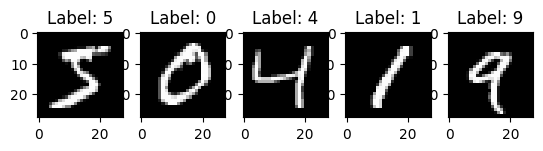

In [4]:
# Plotting 5 MNIST images
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train_mnist[i], cmap='gray')
    plt.title(f"Label: {y_train_mnist[i]}")
plt.show()

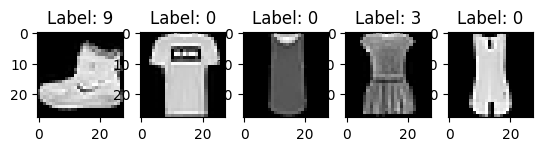

In [5]:
# Plotting 5 Fashion MNIST images
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train_fashion_mnist[i], cmap='gray')
    plt.title(f"Label: {y_train_fashion_mnist[i]}")
plt.show()

# Data preprocessing

In [ ]:
def preprocess_dataset(X_train, y_train, X_test, y_test):
    # Flatten the data to 2D, changing from a 28x28 image to a 784-dimensional vector
    X_train = X_train.reshape(X_train.shape[0], -1)
    X_test = X_test.reshape(X_test.shape[0], -1)
    
    # Normalize the data so that pixel values are in the range [0, 1]
    X_train = X_train / 255.0
    X_test = X_test / 255.0
    
    return X_train, y_train, X_test, y_test

In [ ]:
# Preprocess the MNIST dataset
X_mnist_train, y_mnist_train, X_mnist_test, y_mnist_test = preprocess_dataset(X_train_mnist, y_train_mnist, X_test_mnist, y_test_mnist)

print(X_mnist_train.shape)
print(y_mnist_train.shape)
print(X_mnist_test.shape)
print(y_mnist_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


In [ ]:
# Preprocess the Fashion-MNIST dataset
X_fashion_train, y_fashion_train, X_fashion_test, y_fashion_test = preprocess_dataset(X_train_fashion_mnist, y_train_fashion_mnist, X_test_fashion_mnist, y_test_fashion_mnist)

print(X_fashion_train.shape)
print(y_fashion_train.shape)
print(X_fashion_test.shape)
print(y_fashion_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


# Logistic Regression

In [19]:
logistic_regression_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1500, random_state=42))
])

In [ ]:
start_time_1 = time.time()
logistic_regression_pipeline.fit(X_mnist_train, y_mnist_train)
mnist_training_time = time.time() - start_time_1

start_time_2 = time.time()
mnist_predictions = logistic_regression_pipeline.predict(X_mnist_test)
mnist_prediction_time = time.time() - start_time_2

print(f"Train time for MNIST: {mnist_training_time:.2f} seconds")
print(f"Prediction time for MNIST: {mnist_prediction_time:.2f} seconds")

Train time for MNIST: 11.28 seconds
Prediction time for MNIST: 0.03 seconds


In [38]:
start_time_1 = time.time()
logistic_regression_pipeline.fit(X_fashion_train, y_fashion_train)
fashion_training_time = time.time() - start_time_1

start_time_2 = time.time()
fashion_predictions = logistic_regression_pipeline.predict(X_fashion_test)
fashion_prediction_time = time.time() - start_time_2

print(f"Train time for Fashion-MNIST: {fashion_training_time:.2f} seconds")
print(f"Prediction time for Fashion-MNIST: {fashion_prediction_time:.2f} seconds")

Train time for Fashion-MNIST: 55.81 seconds
Prediction time for Fashion-MNIST: 0.03 seconds


## Metrics

In [30]:
mnist_metrics = {
    "Accuracy": accuracy_score(y_mnist_test, mnist_predictions),
    "Precision": precision_score(y_mnist_test, mnist_predictions, average='macro'),
    "Recall": recall_score(y_mnist_test, mnist_predictions, average='macro'),
    "F1": f1_score(y_mnist_test, mnist_predictions, average='macro'),
}

fashion_metrics = {
    "Accuracy": accuracy_score(y_fashion_test, fashion_predictions),
    "Precision": precision_score(y_fashion_test, fashion_predictions, average='macro'),
    "Recall": recall_score(y_fashion_test, fashion_predictions, average='macro'),
    "F1": f1_score(y_fashion_test, fashion_predictions, average='macro'),
}

print("MNIST Metrics:", mnist_metrics)
print("Fashion-MNIST Metrics:", fashion_metrics)

MNIST Metrics: {'Accuracy': 0.922, 'Precision': 0.9210948016864575, 'Recall': 0.9209336671364807, 'F1': 0.9209397468386704}
Fashion-MNIST Metrics: {'Accuracy': 0.834, 'Precision': 0.832365923964737, 'Recall': 0.834, 'F1': 0.8329980611808523}


In [31]:
mnist_classification_report = classification_report(y_mnist_test, mnist_predictions)
fashion_classification_report = classification_report(y_fashion_test, fashion_predictions)

print("MNIST Classification Report:\n", mnist_classification_report)
print("Fashion-MNIST Classification Report:\n", fashion_classification_report)

MNIST Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.97      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.92      0.89      0.90      1032
           3       0.90      0.91      0.91      1010
           4       0.94      0.93      0.94       982
           5       0.89      0.87      0.88       892
           6       0.94      0.95      0.94       958
           7       0.93      0.92      0.92      1028
           8       0.87      0.88      0.88       974
           9       0.91      0.92      0.92      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000

Fashion-MNIST Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80      1000
           1       0.96      0.96      0.96      1000
          